# WP12 — S07 öncelikli tek deneme; S04 kilitli hazırlık

Bu notebook API çağırmaz; kaynak tablolarını, gerçek mevcut sayaçları ve testleri gösterir. S07 ve S04 henüz **NOT_RUN**. Kullanıcının S01 için olumlu insan beyanı ayrı alındıdır; resmî QA **PENDING** aynen kalır. Bütçe genişletme teklifi yeni sürümdür; eski kayıtlar sıfırlanmaz.

,source_key,physical_page,scope,kind,qualifier_exact,quote_exact,required_context_quote_ids
0,D_class_renal,7,class_level,adverse_context,Inherited tetracycline-class scope;not independent direct-doxycycline evidence,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48;quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b
1,D_class_intro,7,class_level,scope_anchor,Governs following ADR subsections;not drug-specific proof,The following adverse reactions have been observed in patients receiving tetracyclines. \n,NaN
2,D_BUN_exception,4,class_statement_with_doxycycline_exception,warning,Retain BOTH sentences;doxycycline exception in renal-impairment context;not positive doxycycline-BUN label,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indicate that this does not occur \nwith the use of doxycycline in patients with impaired renal function. \n,NaN


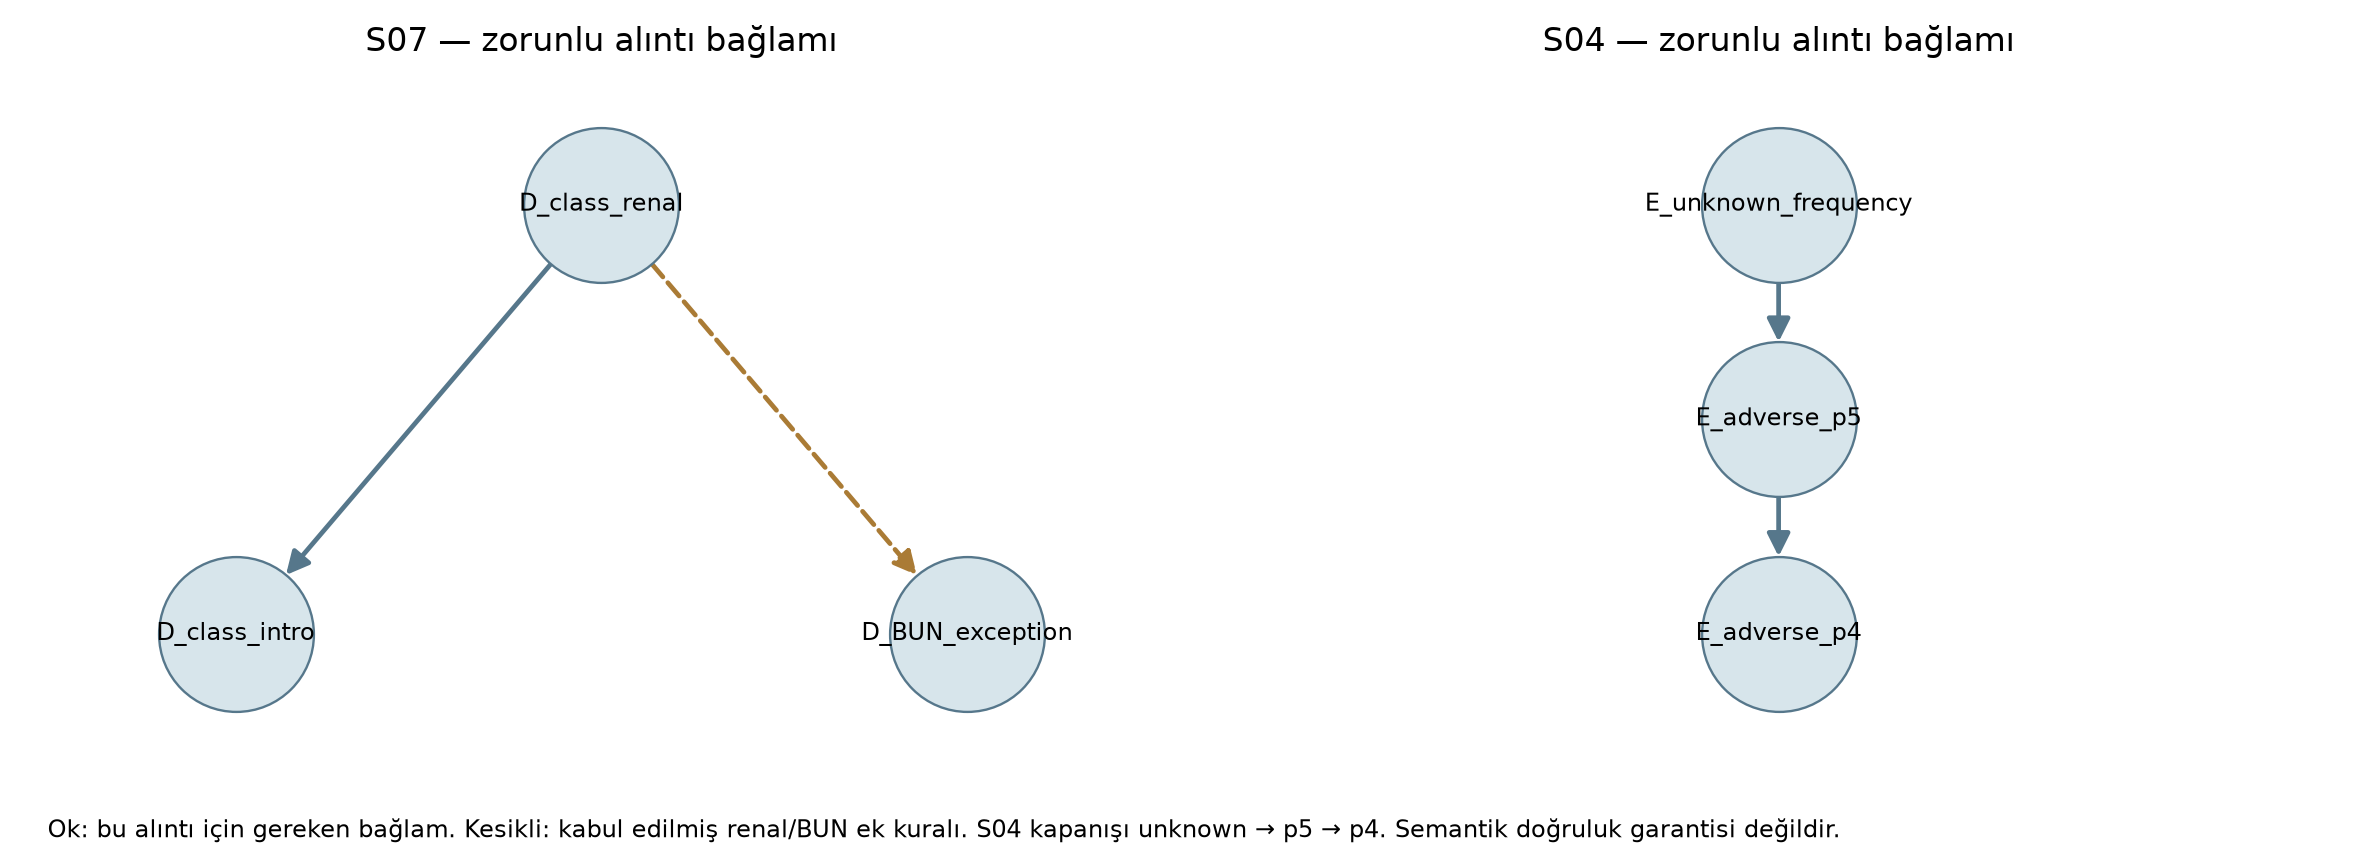

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S07_preparation_v2'
F=ROOT/'reports/figures/WP12/openai_S07_preparation_v2'
table=pd.read_csv(Q/'real_source_dependency_table.csv')
with pd.option_context('display.max_colwidth',None):
    display(table[table.scenario=='S07'][['source_key','physical_page','scope','kind','qualifier_exact','quote_exact','required_context_quote_ids']])
from IPython.display import Image
display(Image(filename=str(F/'01_real_source_dependencies.png')))


**S07 yorumu:** Renal/BUN bildirimi tetracycline sınıfına aittir. Sınıf girişi ve doxycycline istisnasının iki tam cümlesi çıkarılamaz. Kaynak-ID listesinde üçünün bulunması, modelin istisnayı veya “studies to date indicate” koşulunu doğru Türkçeyle aktaracağını kanıtlamaz. Gerçek çıktı ajan ve insan tarafından ayrıca okunacaktır.

## S04 — farklı kanıt türü, yalnız hazırlık

In [2]:

with pd.option_context('display.max_colwidth',None):
    display(table[table.scenario=='S04'][['source_key','physical_page','scope','qualifier_exact','quote_exact','required_context_quote_ids']])
display(pd.read_csv(Q/'scenario_statuses_NOT_RUN.csv'))


,source_key,physical_page,scope,qualifier_exact,quote_exact,required_context_quote_ids
3,E_adverse_p4,4,product_specific,Section4 starts here and continues on physical5,"4. Possible side effects \n \nLike all medicines, this medicine can cause side effects, although not everybody gets \nthem. \n \nIf you notice any of the following, contact your doctor immediately: \n• difficulty breathing \n• fainting \n• swelling of the face, lips or throat \n• skin rashes \n• severe skin reactions including large fluid-filled blisters, sores and ulcers \n• ulcers in the mouth and throat as these may be signs of an allergic reaction \n",NaN
4,E_adverse_p5,5,product_specific,Continuation of section4;retain reporting/frequency context,"• diarrhoea which may be severe or prolonged and may contain blood or mucus \n• serious skin rashes that may involve blistering and can cover large areas of the torso, \n face and limbs (conditions known as Stevens Johnson syndrome, toxic epidermal \n necrolysis and erythema multiforme) \n• various liver or gall-bladder problems, which can cause yellowing of the skin \n and/or eyes (jaundice) or pale stools with dark urine. \n• a life-threatening irregular heart beat called torsades de pointes or abnormal ECG \nheart tracing) or heart stopping (cardiac arrest), \n \nContact a doctor immediately if you experience a serious skin reaction: a red, scaly rash \nwith bumps under the skin and blisters (exanthematous pustulosis). The frequency of this \nside effect is not known (cannot be estimated from the available data). \n \nOther side effects of Erythromycin Tablets include-: \nNot known (frequency cannot be estimated from the available data) \n• feeling sick or being sick, \n• increase in a particular type of white blood cells (eosinophilia), \n• stomach pains; these may be a symptom of an inflamed pancreas (pancreatitis), \n• ringing in the ears (tinnitus), \n• reversible loss of hearing (usually associated with high doses or in patients with kidney \n problems), \n• chest pain, \n• fever, \n• abnormal heart rhythms (including palpitations, a faster heartbeat) \n• confusion, \n• Anorexia, \n• fits (seizures), \n• vertigo (problems with balance that can result in feelings of dizziness or sickness – \n particularly on standing), \n• hallucinations (seeing or hearing things that are not there), \n• feeling generally unwell (malaise), \n• inflammation of the kidneys (a condition known as interstitial nephritis), \n• low blood pressure, \n• visual impairment/blurred vision (Mitochondrial optic neuropathy). \n \nAdditional side effects in children and adolescents \nAdverse drug reactions in children are similar to those in adults. \n \nReporting of side effects \nIf you get any side effects, talk to your doctor or pharmacist. This includes any possible \nside effects not listed in this leaflet. You can also report side effects directly via the Yellow \nCard Scheme at: www.mhra.gov.uk/yellowcard or search for MHRA Yellow Card in the \nGoogle Play or Apple App Store. \nBy reporting side effects you can help provide more information on the safety of this \nmedicine. \n \n \n",quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468
5,E_unknown_frequency,5,product_specific,Frequency not known;no numeric probability,"Other side effects of Erythromycin Tablets include-: \nNot known (frequency cannot be estimated from the available data) \n• feeling sick or being sick, \n• increase in a particular type of white blood cells (eosinophilia), \n• stomach pains; these may be a symptom of an inflamed pancreas (pancreatitis), \n• ringing in the ears (tinnitus), \n• reversible loss of hearing (usually associated with high doses or in patients with kidney \n problems), \n• chest pain, \n• fever, \n• abnormal heart rhythms (including palpitations, a faster heartbeat) \n• confusion, \n• Anorexia, \n• fits (seizures), \n• vertigo (problems with balance that can result in feelings of dizziness or sickness – \n particularly o

,scenario,execution_status,source_quotes,source_characters_with_overlap,actual_prompt_tokens,actual_cost_USD,agent_review,human_review,server_Structured_Outputs_acceptance
0,S07,NOT_RUN,3,380,NaN,NaN,PENDING,PENDING,PENDING_FIRST_REAL_RESPONSE
1,S04,LOCKED_NOT_RUN,3,3803,NaN,NaN,PENDING,PENDING,PENDING_FIRST_REAL_RESPONSE


**S04 yorumu:** Bilinmeyen sıklık alt alıntısı, sayfa5 devamı üzerinden sayfa4 bağlamına bağlıdır. Toplam3803karakter örtüşen alıntıları içerir; sessiz tekilleştirme/kesme yapılmadı. Bilinmeyen sıklık sayısal risk/yaygınlık veya kesin yokluk değildir. S04 şeması hazır olsa da yürütücü S04 bayrağı kabul etmez; S07 sonucu görülmeden çalıştırılamaz.

## Bütçe v2 — teklif ve korunan gerçek sayaç

,HTTP_reservations_total,inference_reservations_total,reserved_USD,within_limits,unknown_prior_cost_not_refunded,actual_invoice_total
0,6,2,0.046,True,True,UNKNOWN_NOT_QUERIED


,sınır,v1,v2_teklif,mevcut
0,HTTP toplam,10.00,30.00,6.000
1,inference toplam,10.00,10.00,2.000
2,Operasyonel rezerv USD,0.24,0.25,0.046


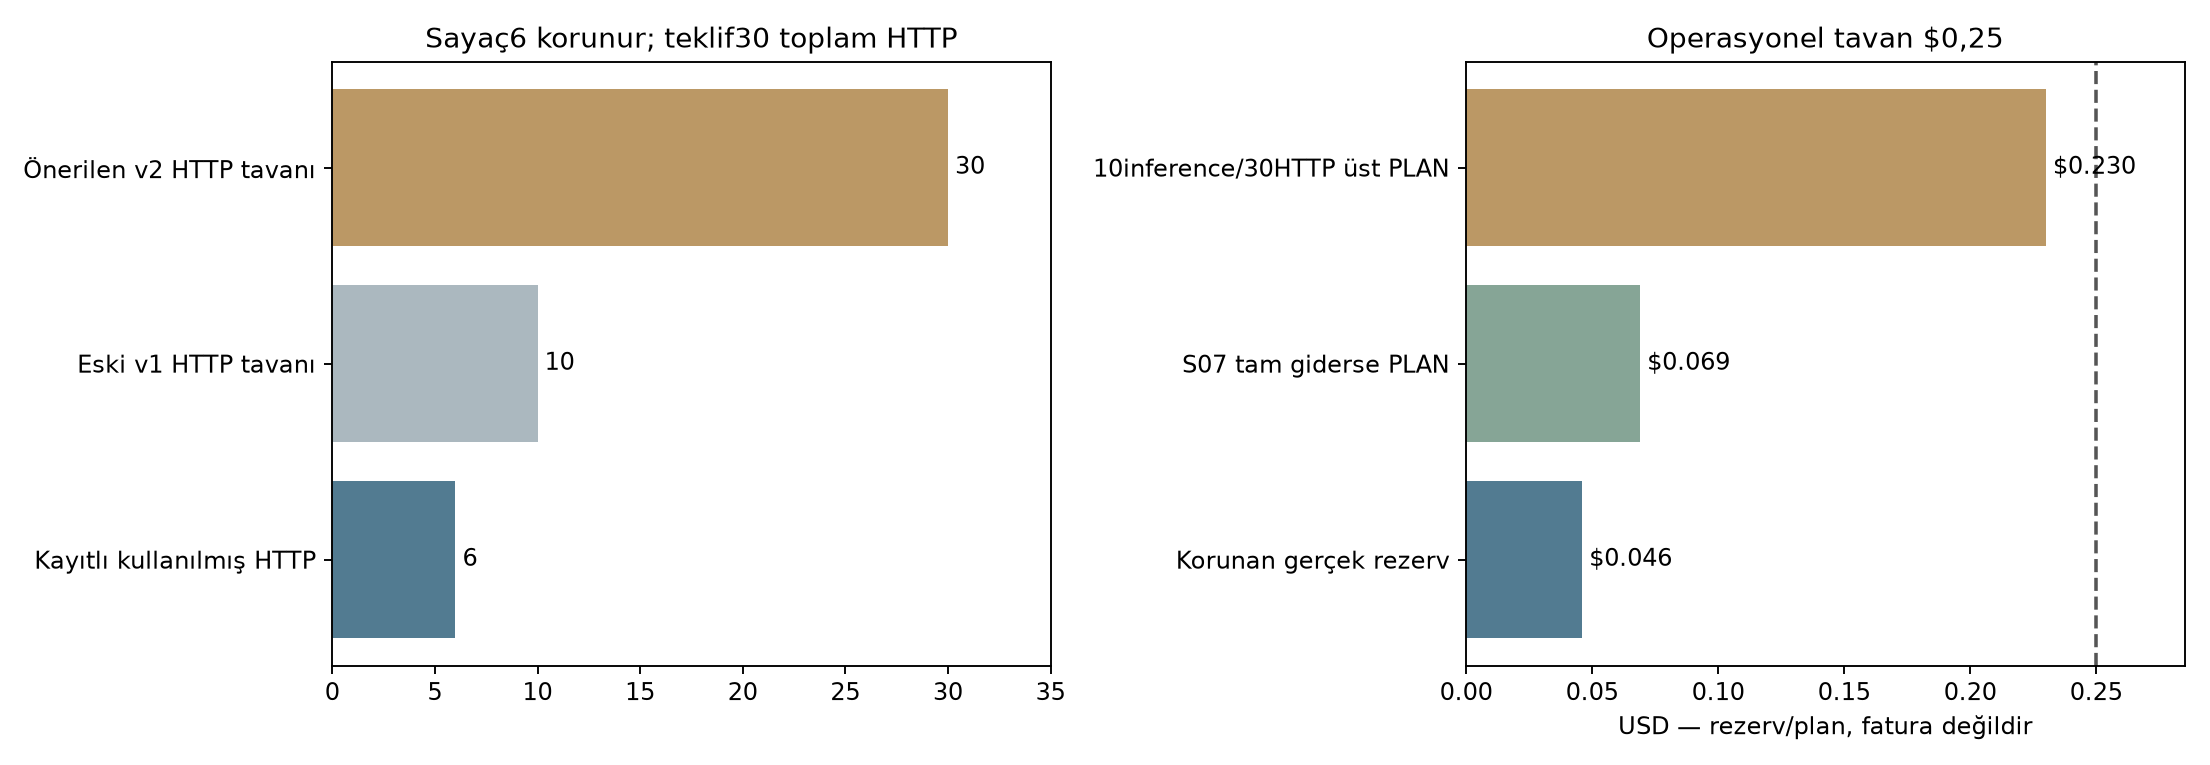

In [3]:

p=json.loads((ROOT/'configs/WP12_OPENAI_SMALL_PILOT_BUDGET_v2.json').read_text(encoding='utf-8'))
baseline=json.loads((Q/'budget_baseline_real_records.json').read_text(encoding='utf-8'));display(pd.DataFrame([baseline]))
display(pd.DataFrame([{'sınır':'HTTP toplam','v1':10,'v2_teklif':30,'mevcut':6},
 {'sınır':'inference toplam','v1':10,'v2_teklif':10,'mevcut':2},
 {'sınır':'Operasyonel rezerv USD','v1':.24,'v2_teklif':.25,'mevcut':.046}]))
display(Image(filename=str(F/'02_budget_v1_and_proposed_v2.png')))


**Yorum:**30HTTP, toplam10inference için gereken3'er çağrının üst planıdır; ek10inference değildir. Eski2rezerv sayılınca en fazla8inference rezerv kapasitesi kalır.10×$0,02 +30×$0,001 =$0,23; $0,25 tavan altında. Bu tur yalnız S07'nin bir üretimi yetkilidir. Her HTTP'de finans/hash, her inference öncesi tam sunucu tokenı/maliyet kapısı vardır. Eski kredi-hatalı maliyet UNKNOWN; tam rezerv korunur. Para bakiyesi/fatura sorgulanmadı.

## Teknik/ajan/insan ayrımı

In [4]:

tests=json.loads((Q/'test_summary.json').read_text(encoding='utf-8'));display(pd.DataFrame([tests]))
display(pd.DataFrame([json.loads((Q/'PowerShell_parse_and_hash.json').read_text(encoding='utf-8'))]))
receipt=json.loads((Q/'S01_positive_user_statement_NOT_FORMAL_QA.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'alan':'S01 kullanıcı beyanı','durum':receipt['user_statement_polarity']},
 {'alan':'Formal insan QA','durum':receipt['formal_QA_status']},
 {'alan':'İnceleyici kimliği','durum':receipt['actual_reviewer_identity']},
 {'alan':'S07 yeni API/ajan/insan sonucu','durum':'NOT_RUN / PENDING / PENDING'}]))


,tests,returncode,new_API_requests,fixtures
0,28,0,0,TEST_ONLY_NOT_MODEL_OUTPUT


,syntax_errors,parser_version,executed,script_sha256,policy_client_pins_match
0,0,5.1.26100.9711,False,00991fe7a3399d2f632fc7e363a994717f564c4c40cce452efab6b749e26f000,True


,alan,durum
0,S01 kullanıcı beyanı,POSITIVE_FOR_TWO_ITEMS
1,Formal insan QA,UNCHANGED_PENDING
2,İnceleyici kimliği,NOT_PROVIDED_NOT_INFERRED_FROM_OS_USERNAME
3,S07 yeni API/ajan/insan sonucu,NOT_RUN / PENDING / PENDING


**Yorum:**28offline testte doğru quote-ID'li yanlış-anlam fixture'ları teknik kapıyı geçebilir; semantic_success null ve insanPENDING kalır. Bu test bir model sonucu değildir, otomatik semantik değerlendirme iddiasının sınırını gösterir. S01 sabit iki cümlesi yeni senaryoların doğrulayıcısı olarak kullanılmaz.

İnsan formal kararı için açık proje inceleyici kimliği/rolü, tam run/response hash'i, item ve quote kapsamı, karar, zaman dilimli tarih ve teyit referansı gerekir. Registry/template aktif değildir; doğrulayıcı yalnız kontrol eder, dosya yazmaz. Kullanıcının olumlu beyanı önceki PENDING dosyasını değiştirmez. S07 yetkisi bu turdaki açık kullanıcı isteğidir.

**Durma noktası:** Normal PowerShell'de `-AcceptBudgetV2 -RunS07` bütçe teklifini yalnız bu tek S07 yürütümü için açıkça kabul eder. Bu notebook gerçek istek göndermez. Yeni yanıtın ham gövde/usage/schema/source dosyaları saklanacak, kaynak anlamı ayrıca incelenecektir. S04/19×3/WP13/yayın/eğitim kapalıdır.

[Bütçe ve adaptör sözleşmesi](../docs/plan/WP12_OPENAI_SMALL_PILOT_BUDGET_v2.md); [insan kontrolü](../docs/plan/WP12_HUMAN_DECISION_CONTROL_v1.md).